# Actividad 4: ingresos, prevención de leakage y auditoría de sesgos

**Análisis de datos II · Resolución individual · 18/10/2026**

Mi objetivo es predecir `income` como una variable continua usando las ocho características disponibles. En esta resolución comparo una regresión lineal en escala original con otra entrenada sobre el logaritmo del ingreso. Elijo por MAE en validación cruzada y evalúo una sola vez el modelo elegido sobre un test reservado. Finalmente, analizo errores por `sex` y `race` y redacto una Model Card.

Uso el archivo local provisto, `census_income.csv`. No asumo que sea el Adult binario ni atribuyo una moneda, un año de relevamiento o un origen real que el archivo no documenta: los errores se expresan en **unidades de ingreso anual**.

In [1]:
from pathlib import Path
import sys, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from fairlearn.metrics import MetricFrame, count

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.options.display.float_format = '{:,.2f}'.format
BASE = Path.cwd() if (Path.cwd() / 'census_income.csv').exists() else Path.cwd() / 'tp_solution'
DATA = BASE / 'census_income.csv'
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)
print('Intérprete:', sys.executable)
assert Path(sys.prefix).name == '.venv', 'Seleccionar el kernel del entorno uv (.venv).'
print('SHA256 del dataset:', hashlib.sha256(DATA.read_bytes()).hexdigest())
df = pd.read_csv(DATA)
display(df.head())
display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'faltantes': df.isna().sum(),
                      'porcentaje_faltante': df.isna().mean() * 100}))
print('Dimensiones originales:', df.shape, '| Duplicados exactos:', df.duplicated().sum())

Python: 3.12.13 | scikit-learn: 1.9.1
Intérprete: /Users/gabrielper12/Projects/CEIA_Analisis_de_datos_II/.venv/bin/python
SHA256 del dataset: ca9f93383d6e5acbe20526992d96ed0b2f672e368036533c3eaa2283caac4092


,age,hours_per_week,education,employer_type,marital_status,sex,race,born_in_us,income
0,55,55.00,Graduate degree,Self-employed (incorporated),Divorced,Male,White,Yes,"279,000.00"
1,20,35.00,High school,Private,Never married,Female,White,Yes,"23,000.00"
2,59,30.00,High school,State government,Divorced,Female,White,Yes,"15,100.00"
3,43,40.00,Some college,State government,Married,Male,Black,Yes,"31,200.00"
4,33,20.00,No high school diploma,Private,Married,Female,Black,Yes,"9,400.00"


,tipo,faltantes,porcentaje_faltante
age,int64,0,0.00
hours_per_week,float64,500,5.00
education,object,300,3.00
employer_type,object,400,4.00
marital_status,object,0,0.00
sex,object,0,0.00
race,object,0,0.00
born_in_us,object,0,0.00
income,float64,0,0.00


Dimensiones originales: (10000, 9) | Duplicados exactos: 86


## Preparación y protocolo de evaluación

Detecté filas exactamente repetidas. Como no hay identificador de persona, no puedo saber si son personas distintas: adopto la decisión conservadora de conservar una sola copia de cada fila completa antes de dividir, para evitar que una observación idéntica aparezca en entrenamiento y evaluación. Esto cambia la población evaluada a registros únicos y es una limitación que documento.

Reservo 20% para test **antes de estudiar la distribución de la target y elegir entre los modelos candidatos**. El 80% restante sirve para exploración y validación cruzada. Supongo registros independientes; sin identificadores ni fechas no puedo asegurar independencia entre personas relacionadas ni generalización temporal.

Los faltantes de entradas se imputan dentro del pipeline, nunca con estadísticas del test. No elimino ingresos altos por su magnitud: pueden ser casos válidos y son parte del problema. Incluyo `sex` y `race` porque la consigna los propone como entradas; esto implica uso directo de atributos sensibles y exige una auditoría. Suprimirlos tampoco garantizaría equidad debido a posibles proxies.

In [2]:
n_original = len(df)
df = df.drop_duplicates().reset_index(drop=True)
assert df['income'].notna().all() and np.isfinite(df['income']).all()
assert (df['income'] > 0).all()
X = df.drop(columns='income')
y = df['income']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
print(f'Registros únicos: {len(df)}; removidos: {n_original-len(df)}')
print(f'Desarrollo: {len(X_train)}; test reservado: {len(X_test)}')
display(y_train.describe(percentiles=[.5, .9, .95, .99]).to_frame('income (desarrollo)'))

Registros únicos: 9914; removidos: 86
Desarrollo: 7931; test reservado: 1983


,income (desarrollo)
count,"7,931.00"
mean,"54,916.42"
std,"68,602.52"
min,110.00
50%,"36,900.00"
90%,"110,600.00"
95%,"152,150.00"
99%,"471,000.00"
max,"1,096,000.00"


## Parte 1.a · Distribución y transformación de la target

Elijo el **logaritmo natural** porque los ingresos son estrictamente positivos y su distribución presenta asimetría a la derecha. Comprime la cola alta, no requiere estimar un parámetro y su inversa es `exp`. Box-Cox también es válida para positivos, pero añade un λ que debería estimarse dentro de cada fold; Yeo-Johnson permite ceros y negativos, algo que este archivo no necesita. La simplicidad del log justifica empezar por él.

La normalidad de la target no es un requisito de la regresión lineal y una target más simétrica no garantiza residuos normales ni menor MAE. Comparo los errores para comprobar su utilidad.

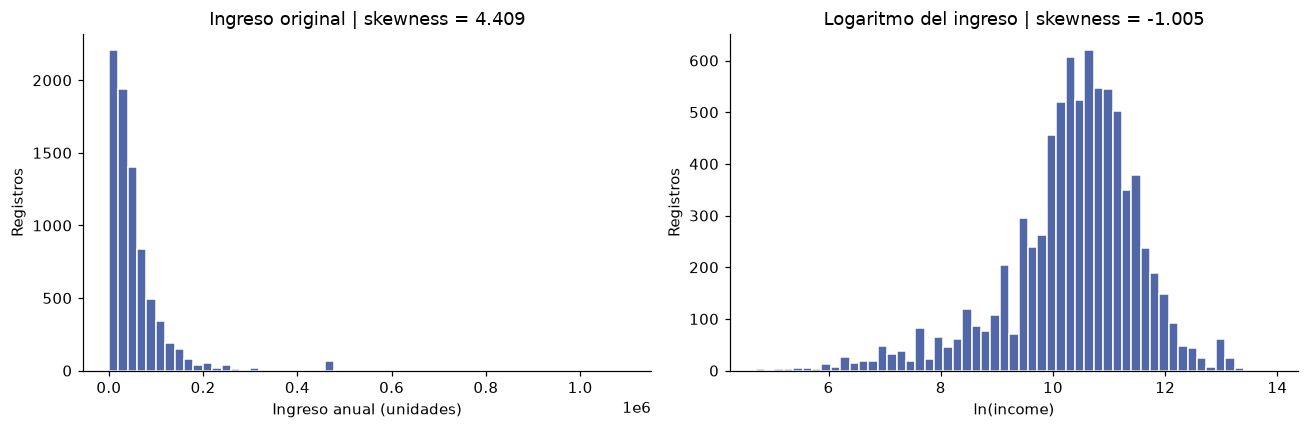

En desarrollo, obtuve una skewness de **4.409** en la target original y **-1.005** luego del log. La comparación muestra cuánto cambia la asimetría sin consultar la target del test.

In [3]:
y_log = np.log(y_train)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, title, xlabel in zip(axes, [y_train, y_log],
        ['Ingreso original', 'Logaritmo del ingreso'], ['Ingreso anual (unidades)', 'ln(income)']):
    ax.hist(values, bins=55, color='#5267a7', edgecolor='white')
    ax.set(title=f'{title} | skewness = {values.skew():.3f}', xlabel=xlabel, ylabel='Registros')
plt.tight_layout()
plt.show()
display(Markdown(f"En desarrollo, obtuve una skewness de **{y_train.skew():.3f}** en la target original y **{y_log.skew():.3f}** luego del log. La comparación muestra cuánto cambia la asimetría sin consultar la target del test."))

## Parte 1.b · Regresión lineal y k-fold sin data leakage

Uso cinco folds con mezcla y semilla fija. Ambos modelos comparten exactamente las mismas particiones y el mismo preprocesamiento: mediana y estandarización en numéricas; categoría constante `Sin dato` y one-hot en categóricas. El encoder usa una categoría de referencia por variable. Si aparece una categoría no vista durante el ajuste, la codifica con ceros en el bloque correspondiente; esto evita un error de ejecución, aunque no permite estimar un efecto específico para esa categoría.

`cross_validate` clona y ajusta el pipeline completo en cada fold. Así, medianas, medias, escalas y categorías se aprenden solo con el entrenamiento de ese fold. `income` queda fuera de las entradas. `TransformedTargetRegressor` aplica log durante el ajuste y `exp` al predecir: el MAE de ambos candidatos se calcula en la **escala original**. No comparo MAE en log con MAE en ingresos.

No agrego selección de variables, interacciones ni búsqueda de parámetros sin una necesidad demostrada: la comparación mantiene fija la especificación lineal para aislar el efecto de transformar la target. Agrego una mediana constante como referencia mínima para el MAE.

In [4]:
numericas = ['age', 'hours_per_week']
categoricas = ['education', 'employer_type', 'marital_status', 'sex', 'race', 'born_in_us']
preproceso = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                      ('escalar', StandardScaler())]), numericas),
    ('cat', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='Sin dato')),
                      ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), categoricas)
])
lineal = Pipeline([('preproceso', preproceso), ('regresion', LinearRegression())])
modelos = {
    'Lineal original': lineal,
    'Lineal log': TransformedTargetRegressor(regressor=clone(lineal), func=np.log, inverse_func=np.exp),
    'Baseline mediana': DummyRegressor(strategy='median')
}
folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train))
filas = []
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=folds,
                            scoring={'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'},
                            n_jobs=1, error_score='raise')
    for fold, (mae, rmse) in enumerate(zip(-scores['test_mae'], -scores['test_rmse']), 1):
        filas.append({'modelo': nombre, 'fold': fold, 'MAE': mae, 'RMSE': rmse})
cv_detalle = pd.DataFrame(filas)
cv_resumen = cv_detalle.groupby('modelo').agg(MAE_medio=('MAE','mean'), MAE_sd=('MAE','std'),
                                            RMSE_medio=('RMSE','mean')).sort_values('MAE_medio')
display(cv_detalle.pivot(index='fold', columns='modelo', values='MAE'))
display(cv_resumen)
candidatos = ['Lineal original', 'Lineal log']
nombre_final = cv_resumen.loc[candidatos, 'MAE_medio'].idxmin()
mejora_cv = 100 * (1 - cv_resumen.loc['Lineal log','MAE_medio'] / cv_resumen.loc['Lineal original','MAE_medio'])
display(Markdown(f"**Elijo {nombre_final}** por el menor MAE medio de validación. El cambio relativo del MAE con log es una reducción de **{mejora_cv:.2f}%** (un valor negativo indicaría empeoramiento). La desviación entre folds describe variabilidad; no es un intervalo de confianza ni una prueba de significación."))

modelo,Baseline mediana,Lineal log,Lineal original
fold,,,
1,"39,233.52","30,976.25","32,195.94"
2,"41,004.69","31,575.99","32,729.08"
3,"34,510.46","28,674.41","30,198.03"
4,"34,914.49","28,091.83","30,682.93"
5,"33,393.64","28,420.63","31,352.26"


,MAE_medio,MAE_sd,RMSE_medio
modelo,,,
Lineal log,"29,547.82","1,605.24","61,697.15"
Lineal original,"31,431.65","1,043.57","58,558.84"
Baseline mediana,"36,611.36","3,309.98","70,577.36"


**Elijo Lineal log** por el menor MAE medio de validación. El cambio relativo del MAE con log es una reducción de **5.99%** (un valor negativo indicaría empeoramiento). La desviación entre folds describe variabilidad; no es un intervalo de confianza ni una prueba de significación.

## Parte 1.c · Interpretación y evaluación final

La regresión original minimiza error cuadrático en ingresos y tiende a priorizar errores grandes. Al entrenar con log, minimizo error cuadrático en otra escala, reduciendo la influencia de ingresos muy altos. `exp` del pronóstico logarítmico no estima automáticamente la media condicional del ingreso (por la no linealidad de la exponencial); si la media condicional de log(income) está correctamente especificada y los errores son condicionalmente simétricos, se relaciona con la mediana condicional, que puede convenir para MAE. No aplico corrección de retransformación para la media porque el criterio principal es MAE.

La comparación solicitada queda resuelta con MAE fuera de muestra por fold. Ahora ajusto el candidato elegido con todo desarrollo y lo evalúo en el test reservado; no vuelvo a elegir el modelo con estos resultados.

**Lectura de los resultados obtenidos.** La skewness pasó de 4,409 a -1,005: disminuyó su magnitud, pero quedó asimetría hacia la izquierda. Por eso no concluyo que la distribución transformada sea normal. En validación, el MAE medio bajó de 31.431,65 a 29.547,82 (5,99%), y el modelo con log obtuvo menor MAE en los cinco folds. Sin embargo, el RMSE medio subió de 58.558,84 a 61.697,15. La transformación mejora el criterio que elegí, pero empeora el error que penaliza más los desvíos grandes; no es una mejora en todas las métricas.

,Test final
MAE,"29,439.16"
RMSE,"60,908.87"
R2,0.17


MAE baseline mediana en test: 35,590.13
Predicciones negativas: 0


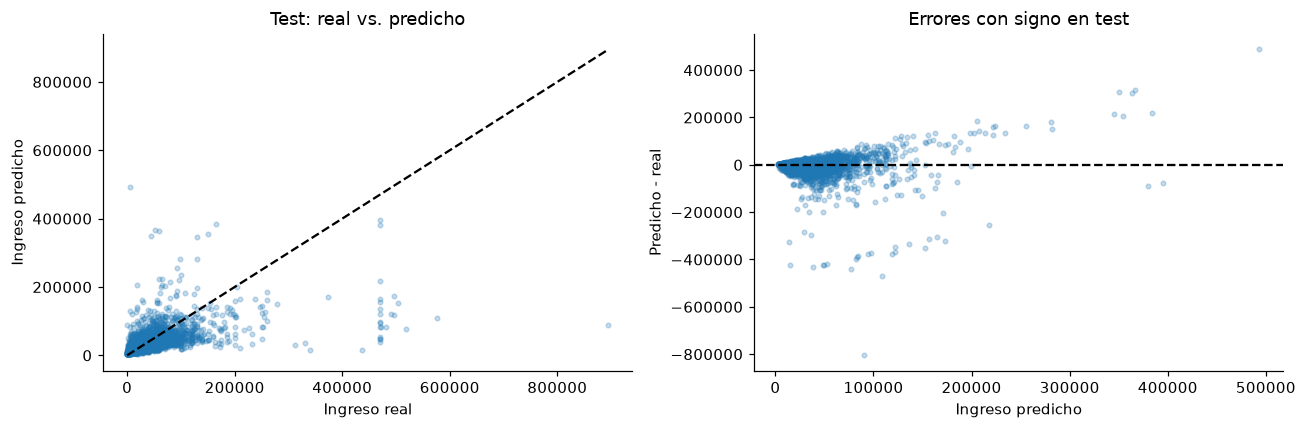

En test, mi modelo obtiene **MAE = 29,439.16**, frente a **35,590.13** del predictor constante. El RMSE de **60,908.87** permite apreciar el peso de errores grandes. No interpreto esta diferencia como garantía sobre otra población; el gráfico deja visibles los casos extremos.

In [5]:
modelo_final = clone(modelos[nombre_final]).fit(X_train, y_train)
pred = modelo_final.predict(X_test)
assert np.isfinite(pred).all()
metricas_test = pd.Series({'MAE': mean_absolute_error(y_test, pred),
                          'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
                          'R2': r2_score(y_test, pred)}, name='Test final')
baseline = DummyRegressor(strategy='median').fit(X_train, y_train)
mae_base_test = mean_absolute_error(y_test, baseline.predict(X_test))
display(metricas_test.to_frame())
print(f'MAE baseline mediana en test: {mae_base_test:,.2f}')
print(f'Predicciones negativas: {(pred < 0).sum()}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, pred, alpha=.25, s=9)
lim = max(y_test.max(), pred.max())
axes[0].plot([0,lim],[0,lim], '--', color='black')
axes[0].set(xlabel='Ingreso real', ylabel='Ingreso predicho', title='Test: real vs. predicho')
axes[1].scatter(pred, pred-y_test.to_numpy(), alpha=.25, s=9)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Ingreso predicho', ylabel='Predicho - real', title='Errores con signo en test')
plt.tight_layout(); plt.show()
display(Markdown(f"En test, mi modelo obtiene **MAE = {metricas_test['MAE']:,.2f}**, frente a **{mae_base_test:,.2f}** del predictor constante. El RMSE de **{metricas_test['RMSE']:,.2f}** permite apreciar el peso de errores grandes. No interpreto esta diferencia como garantía sobre otra población; el gráfico deja visibles los casos extremos."))

**Interpretación del test.** El R² de 0,172 indica una capacidad explicativa limitada en este conjunto: el modelo reduce aproximadamente un 17,2% la suma de errores cuadrados respecto de predecir la media del propio test, que es la referencia usada en la definición de R². Esto es distinto del baseline de mediana entrenado en desarrollo que uso para comparar MAE. El MAE final de 29.439,16 es aproximadamente un 17,3% menor que el de ese baseline (35.590,13), pero sigue siendo un error considerable.

## Parte 2.a · Auditoría por sexo y raza

Uso `MetricFrame` como en clase, adaptado a regresión. Calculo MAE, RMSE, cantidad de casos y error medio con signo (`predicho - real`): negativo indica subestimación. Agrego ingreso medio y MAE/ingreso medio para contextualizar escalas; este último **no es MAPE** ni certifica equidad.

No uso demographic parity, equalized odds ni la regla del 80% porque aquí no hay clasificación, tasa de aprobación ni umbral de decisión. Diferencias de MAE son señales de disparidad de error; no prueban por sí solas discriminación causal. Las etiquetas históricas podrían reflejar desigualdades y un menor error puede significar reproducirlas mejor.

### Resultados por `sex`

,n,MAE,RMSE,Error_medio,Ingreso_medio,MAE_sobre_ingreso_medio
sex,,,,,,
Female,993,"21,721.34","41,952.23","-7,720.73","40,993.92",0.53
Male,990,"37,180.35","75,270.84","-12,326.03","66,637.48",0.56


Observo el mayor MAE en **Male** (37,180.35) y el menor en **Female** (21,721.34). La brecha absoluta es **15,459.01** y la razón máximo/mínimo es **1.71**. Comparo estos valores junto al ingreso medio y al tamaño de cada grupo, sin adoptar un umbral universal de equidad.

### Resultados por `race`

,n,MAE,RMSE,Error_medio,Ingreso_medio,MAE_sobre_ingreso_medio
race,,,,,,
Asian,88,"27,640.53","40,156.02","-7,487.58","50,515.80",0.55
Black,460,"20,098.07","35,977.85","-8,886.91","42,020.00",0.48
Other or multiple,83,"17,846.13","32,548.79","3,190.28","32,399.88",0.55
White,1352,"33,446.11","69,505.08","-11,381.18","59,330.10",0.56


Observo el mayor MAE en **White** (33,446.11) y el menor en **Other or multiple** (17,846.13). La brecha absoluta es **15,599.97** y la razón máximo/mínimo es **1.87**. Comparo estos valores junto al ingreso medio y al tamaño de cada grupo, sin adoptar un umbral universal de equidad.

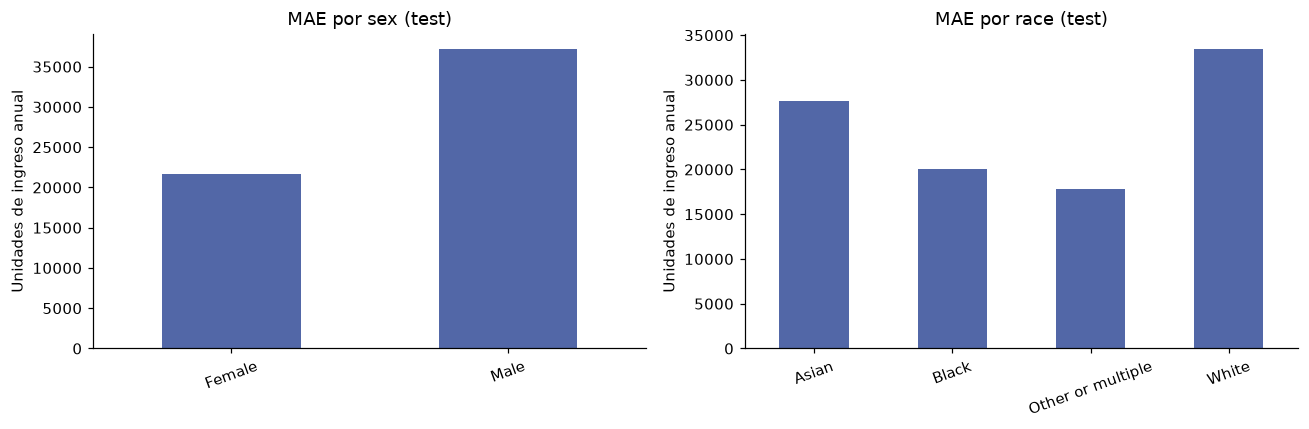

In [6]:
def error_medio(real, estimado):
    return float(np.mean(np.asarray(estimado) - np.asarray(real)))
def rmse(real, estimado):
    return float(np.sqrt(mean_squared_error(real, estimado)))
metricas_grupo = {'n': count, 'MAE': mean_absolute_error, 'RMSE': rmse, 'Error_medio': error_medio}
auditorias = {}
for atributo in ['sex', 'race']:
    mf = MetricFrame(metrics=metricas_grupo, y_true=y_test, y_pred=pred,
                     sensitive_features=X_test[atributo])
    tabla = mf.by_group.copy()
    tabla['n'] = tabla['n'].astype(int)
    tabla['Ingreso_medio'] = y_test.groupby(X_test[atributo]).mean()
    tabla['MAE_sobre_ingreso_medio'] = tabla['MAE'] / tabla['Ingreso_medio']
    auditorias[atributo] = tabla
    display(Markdown(f'### Resultados por `{atributo}`'))
    display(tabla)
    mayor, menor = tabla['MAE'].idxmax(), tabla['MAE'].idxmin()
    display(Markdown(f"Observo el mayor MAE en **{mayor}** ({tabla.loc[mayor,'MAE']:,.2f}) y el menor en **{menor}** ({tabla.loc[menor,'MAE']:,.2f}). La brecha absoluta es **{tabla['MAE'].max()-tabla['MAE'].min():,.2f}** y la razón máximo/mínimo es **{tabla['MAE'].max()/tabla['MAE'].min():.2f}**. Comparo estos valores junto al ingreso medio y al tamaño de cada grupo, sin adoptar un umbral universal de equidad."))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (atributo, tabla) in zip(axes, auditorias.items()):
    tabla['MAE'].plot.bar(ax=ax, color='#5267a7', rot=20)
    ax.set(title=f'MAE por {atributo} (test)', ylabel='Unidades de ingreso anual', xlabel='')
plt.tight_layout(); plt.show()

### Interpretación de los errores por grupo

En `sex`, el modelo subestima en promedio ambos grupos: el error con signo es -7.720,73 en `Female` y -12.326,03 en `Male`. El MAE absoluto es mayor en `Male`, cuyo ingreso medio también es mayor. Al dividir MAE por ingreso medio, la diferencia se reduce: aproximadamente 0,53 frente a 0,56. Esta comparación contextualiza la brecha, pero no demuestra que se deba únicamente al nivel de ingresos ni elimina el problema de equidad.

En `race`, observo subestimación media en `Asian`, `Black` y `White`, y sobreestimación media en `Other or multiple` (+3.190,28). El grupo `White` tiene el mayor MAE absoluto; el cociente MAE/ingreso medio va aproximadamente de 0,48 (`Black`) a 0,56 (`White`). Las diferencias agregadas pueden ocultar errores individuales en ambas direcciones. Además, `Asian` y `Other or multiple` tienen solo 88 y 83 casos en test, frente a 1.352 de `White`, por lo que evito generalizaciones fuertes.

### Incertidumbre de las brechas

Para no interpretar una diferencia puntual como definitiva, estimo intervalos bootstrap percentiles del 95% para diferencias de MAE entre grupos con referencia fija (`Male` para sexo, `White` para raza). Remuestreo errores dentro de cada grupo del test 1.000 veces. Esto describe incertidumbre muestral condicionada al modelo y a este test; no incluye variación de reentrenamiento, sesgo de selección ni causalidad. No ajusto los intervalos por comparaciones múltiples: los interpreto como contrastes exploratorios individuales, no como una conclusión conjunta al 95% sobre todos los grupos.

In [7]:
rng = np.random.default_rng(SEED)
errores_abs = pd.Series(np.abs(pred-y_test.to_numpy()), index=y_test.index)
intervalos = []
for atributo, referencia in [('sex','Male'), ('race','White')]:
    grupos = X_test[atributo]
    ref = errores_abs[grupos == referencia].to_numpy()
    for grupo in sorted(grupos.unique()):
        if grupo == referencia:
            continue
        vals = errores_abs[grupos == grupo].to_numpy()
        difs = np.array([rng.choice(vals, len(vals), replace=True).mean() -
                         rng.choice(ref, len(ref), replace=True).mean() for _ in range(1000)])
        low, high = np.quantile(difs, [.025,.975])
        intervalos.append({'atributo': atributo, 'grupo': grupo, 'referencia': referencia,
                           'diferencia_MAE': vals.mean()-ref.mean(), 'IC95_inf': low, 'IC95_sup': high})
intervalos = pd.DataFrame(intervalos)
display(intervalos)
for row in intervalos.itertuples():
    lectura = 'incluye cero; no tengo evidencia clara de una diferencia en este contraste' if row.IC95_inf <= 0 <= row.IC95_sup else 'excluye cero; hay evidencia muestral de una diferencia de error'
    display(Markdown(f'- **{row.grupo} frente a {row.referencia}:** el intervalo {lectura}.'))

,atributo,grupo,referencia,diferencia_MAE,IC95_inf,IC95_sup
0,sex,Female,Male,"-15,459.01","-20,118.81","-10,838.52"
1,race,Asian,White,"-5,805.58","-12,962.78",938.18
2,race,Black,White,"-13,348.04","-17,350.29","-9,050.41"
3,race,Other or multiple,White,"-15,599.97","-22,111.89","-8,042.55"


- **Female frente a Male:** el intervalo excluye cero; hay evidencia muestral de una diferencia de error.

- **Asian frente a White:** el intervalo incluye cero; no tengo evidencia clara de una diferencia en este contraste.

- **Black frente a White:** el intervalo excluye cero; hay evidencia muestral de una diferencia de error.

- **Other or multiple frente a White:** el intervalo excluye cero; hay evidencia muestral de una diferencia de error.

Mi conclusión es que debo distinguir **disparidad predictiva**, **diferencias observadas de ingreso entre grupos** y **discriminación causal**. Las tablas permiten evaluar las dos primeras de forma descriptiva, pero no identificar la tercera. No atribuyo una causa a sexo o raza a partir de estas asociaciones. Los grupos con pocos registros requieren especial cautela y el bootstrap no corrige su posible falta de representatividad.

Como próximos pasos propondría verificar procedencia y calidad de las etiquetas, ampliar la muestra de grupos pequeños y analizar intersecciones sexo-raza. Evaluaría excluir atributos sensibles y posibles proxies como un experimento con nueva validación, comparando el compromiso entre MAE y brechas. **No implementé una mitigación ni afirmo que el modelo sea justo.**

## Parte 2.b · Model Card

Las fichas con los resultados calculados para mantener alineados el modelo, las métricas y la documentación. Se guarda en data_card.md y model_card.md